In [38]:
#| include: false
import matplotlib.pyplot as plt
import numpy as np
import polars as pl
import seaborn as sns

from utils.style import COLORS, CYCLE, apply_style

apply_style()
np.set_printoptions(precision=4, suppress=True, linewidth=110)
_ = pl.Config.set_float_precision(4)

::: {.callout-tip}
## Learning outcomes

After this topic you should be able to:

1. Explain what statistics studies and distinguish descriptive statistics from
   statistical inference.
2. Identify, in a concrete problem, the population, the individuals, the
   subpopulations and the sample.
3. Distinguish between a **parameter** and a **statistic**, and understand why a
   statistic changes from one sample to another.
4. Classify a variable by its type and measurement scale, and know which
   summaries make sense for each one ([part 2 of this topic](02-types-of-variables.ipynb)).
:::

## What is statistics?

Many everyday questions are about groups that are too large to be observed
completely, or about things that vary from one case to another. How much does a
flat cost in Madrid? Is it much more expensive in the centre than in the outskirts?
Have house prices gone up this year? None of these questions can be answered with
a single observation. We have to **collect data, summarise them and draw
conclusions**, and say how sure we are of those conclusions.

::: {.callout-note}
## Definition

**Statistics** is the discipline that studies how to collect, organise, summarise
and analyse data, and how to draw conclusions and make decisions from them under
uncertainty.
:::

Two ideas in this definition are essential:

- **Variability.** If all flats had the same price, looking at one would be enough.
  Statistics exists because individuals differ. What it studies is not each
  individual but the **distribution** of a characteristic in a group: how many
  flats cost less than 200,000 €, which prices are typical, how different they are.
- **Uncertainty.** We rarely observe the whole group. Conclusions drawn from a part
  of it can be wrong, and statistics tells us by how much.

### Branches of statistics

- **Descriptive statistics** summarises and displays the observed data with tables,
  graphs and a few numbers. Its conclusions refer only to the data at hand. It is
  the subject of this course.
- **Statistical inference** uses the data of a sample to draw conclusions about the
  population it comes from, together with a measure of their reliability.
- **Probability** is the language that connects both: it describes how samples are
  generated, and so how much they can differ from the population.

Every data analysis begins, and often ends, with a careful description of the data.

```{mermaid}
%%| echo: false
%%| label: fig-cycle
%%| fig-cap: "Statistical reasoning. Probability describes how samples are generated from the population; inference goes the opposite way."
flowchart LR
    P["Population<br/>(unknown parameters)"] -- "sampling<br/>(probability)" --> M["Sample<br/>(observed data)"]
    M -- "descriptive<br/>statistics" --> R["Summaries<br/>(statistics)"]
    R -- "statistical<br/>inference" --> P
```

### Statistics in practice

- **Official statistics.** The unemployment rate published by the Spanish National
  Statistics Institute (INE) comes from the *Labour Force Survey*, which interviews
  a sample of households every quarter. The INE housing price index is computed
  from the sales registered by notaries.
- **Economics and business.** Banks value dwellings before granting a mortgage, and
  property portals estimate prices from the characteristics of similar dwellings.
- **Health.** Clinical trials compare treatments on samples of patients.
- **Engineering.** Quality control checks samples of products from a production line.
- **Public policy.** Does a rent subsidy help young people leave their parents'
  home? Answering requires comparing groups and separating the effect of the policy
  from random variability.

## Our data: dwellings for sale in Madrid

Throughout the course we use real data: the **listings of dwellings for sale in the
city of Madrid** published on the property portal idealista in 2018 [@reyblanco2024].
Each row is a dwelling advertised for sale, with its asking price, its size, its
location and its features (lift, terrace, condition…). The data are described in
`data/processed/idealista/README.md`.

In [39]:
listings = pl.read_csv("data/processed/idealista/madrid_listings_2018.csv")

listings.select("district", "price", "area_m2", "bedrooms", "lift").head()

district,price,area_m2,bedrooms,lift
Hortaleza,"255,000.0",97,3,True
Puente de Vallecas,"82,000.0",62,2,True
Puente de Vallecas,"133,000.0",67,3,False
Ciudad Lineal,"204,000.0",180,3,True
Carabanchel,"161,000.0",54,2,False


In [40]:
print(f"Number of listings: {listings.height:,}")

Number of listings: 75,735


## Populations, individuals and samples

### Population and individuals

::: {.callout-note}
## Definition

- **Population**: the set of all the elements we want to study. Its number of
  elements, the **population size**, is denoted by $N$.
- **Individual** (or statistical unit): each element of the population.
:::

Individuals need not be people: they can be dwellings, households, firms,
municipalities or months. Defining the population precisely is the first step of
any study, and requires saying **who**, **where** and **when**.

::: {.callout-tip}
## Example: what exactly do our data describe?

Our individuals are **listings**: dwellings advertised for sale in the city of
Madrid on one portal during 2018. This is not the same as "the dwellings of Madrid"
(most of them were not for sale) or "the dwellings sold in Madrid" (some listings
were never sold, and many sales are not advertised on that portal). The prices are
**asking prices** chosen by the sellers, usually higher than the price finally
agreed. Every conclusion we draw refers to the population of listings, not to the
others.
:::

### Subpopulations

::: {.callout-note}
## Definition

A **subpopulation** is a subset of the population defined by a characteristic of
its individuals.
:::

Subpopulations allow us to study differences within the population: the listings
of the Salamanca district, those with a terrace, or the newly built ones. When the
population is divided into disjoint subpopulations that cover it completely (for
example, the 21 districts of Madrid), they are called **strata**.

### Census and sample

::: {.callout-note}
## Definition

- **Census**: a study in which all the individuals of the population are observed.
- **Sample**: the subset of the population that is actually observed. Its number of
  elements, the **sample size**, is denoted by $n$.
:::

Why not always observe the whole population?

- **Cost and time.** Visiting and valuing every dwelling of Madrid would take years.
  A well-chosen sample gives precise results for a fraction of the cost.
- **Populations that cannot be listed.** The buyers a developer will have next year
  do not exist yet.
- **Destructive tests.** To check how long a battery lasts, it has to be run down.
- **Quality.** A careful survey of a sample can contain fewer errors than a hasty
  census.

### Representative samples and random sampling

A sample is useful only if it is **representative**: its composition resembles that
of the population, apart from differences due to chance. The way to guarantee this
is to choose it **at random**.

::: {.callout-note}
## Definition

A **simple random sample** (without replacement) of size $n$ from a population of
size $N$ is a sample chosen so that each of the $\binom{N}{n}$ possible groups of $n$
individuals has the same probability, $1 / \binom{N}{n}$, of being selected.
:::

In a simple random sample of size $n$, every individual has probability $n/N$ of being
in the sample.

Official surveys use more elaborate random designs (for example, choosing
municipalities first and then households within them), but the principle is the
same: **chance decides who is in the sample, not the researcher or the
respondent**.

::: {.callout-note}
## Historical note: the *Literary Digest* poll (1936)

Before the 1936 US presidential election, the magazine *Literary Digest* mailed
about 10 million ballots and received some 2.4 million replies. It predicted a clear
victory for Alf Landon, but Franklin D. Roosevelt won by a landslide. The addresses
came largely from lists of telephone subscribers and car owners, people with
above-average income during the Great Depression, and only the most motivated
replied [@squire1988]. The same year, George Gallup predicted Roosevelt's victory
with a much smaller sample chosen to mirror the electorate.

A huge but **biased** sample does not correct its bias. A small but **random**
sample allows reliable conclusions.
:::

Other common biases in real data:

- **Non-response**: people who do not answer a survey may differ from those who do.
- **Survivorship**: studying only the shops that are still open overstates how well
  shops do.
- **Self-selection**: an online poll collects the opinion of those who decide to
  take part. Our listings are self-selected too: they are the dwellings whose
  owners chose to sell, and to advertise them on that portal.

### Parameters and statistics

::: {.callout-note}
## Definition

- A **parameter** is a number that describes the **population**. It is fixed, but
  usually unknown.
- A **statistic** is a number computed from the data of a **sample**. It is known
  once the sample has been observed, but it **changes from one sample to another**.
:::

We use Greek letters for parameters and Latin letters for statistics:

| Quantity | Population (parameter) | Sample (statistic) |
|---|---|---|
| Size | $N$ | $n$ |
| Mean | $\mu = \dfrac{1}{N}\displaystyle\sum_{i=1}^{N} x_i$ | $\bar{x} = \dfrac{1}{n}\displaystyle\sum_{i=1}^{n} x_i$ |
| Variance | $\sigma^2$ | $s^2$ |
| Proportion | $p$ | $\hat{p}$ |

: Notation for parameters and statistics.

Let us see the difference with an experiment. Suppose, **for illustration only**,
that the 75,735 listings are the whole population. Then the mean asking price of
all of them is a parameter, $\mu$, which we can compute exactly:

In [41]:
population = listings
mu = population["price"].mean()
print(f"N = {population.height:,} listings  ·  μ = {mu:,.0f} €")

N = 75,735 listings  ·  μ = 388,892 €


Now we draw five simple random samples of $n = 30$ listings and compute the mean
price $\bar{x}$ of each one:

In [42]:
means = [
    population.sample(n=30, seed=seed)["price"].mean()
    for seed in range(5)
]
pl.DataFrame({"sample": range(1, 6), "sample mean (€)": means})

sample,sample mean (€)
1,"388,066.7"
2,"470,133.3"
3,"487,300.0"
4,"446,166.7"
5,"332,300.0"


Each sample gives a different $\bar{x}$, and none of them equals $\mu$. If we repeat
the experiment many times we can see how the statistic is distributed:

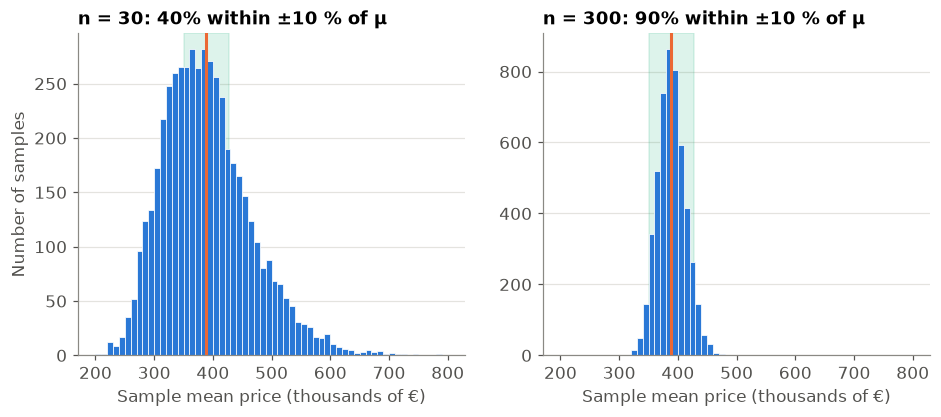

In [43]:
#| label: fig-sample-means
#| fig-cap: "Mean asking price in 5,000 simple random samples of 30 listings (left) and of 300 listings (right). The vertical line marks the population mean μ, and the shaded band μ ± 10 %."
rng = np.random.default_rng(1)
prices = population["price"].to_numpy()
tolerance = 0.10 * mu  # the error we accept: ±10 % of the true value

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharex=True)
rows = []
for ax, n in zip(axes, [30, 300]):
    means = np.array([rng.choice(prices, size=n, replace=False).mean() for _ in range(5_000)])
    close = np.abs(means - mu) <= tolerance
    rows.append({"n": n,
                 "mean of the sample means (€)": means.mean(),
                 "sd of the sample means (€)": means.std(),
                 "share within ±10 % of μ": close.mean()})

    ax.axvspan((mu - tolerance) / 1000, (mu + tolerance) / 1000, color=COLORS["teal"], alpha=0.15)
    ax.hist(means / 1000, bins=np.arange(200, 805, 10), color=COLORS["blue"],
            edgecolor="white", linewidth=0.5)
    ax.axvline(mu / 1000, color=COLORS["orange"], linewidth=2)
    ax.set_title(f"n = {n}: {close.mean():.0%} within ±10 % of μ")
    ax.set_xlabel("Sample mean price (thousands of €)")
axes[0].set_ylabel("Number of samples")
plt.show()

In [44]:
print(f"Population mean μ = {mu:,.0f} €")
pl.DataFrame(rows)

Population mean μ = 388,892 €


n,mean of the sample means (€),sd of the sample means (€),share within ±10 % of μ
30,"389,577.0","75,457.7",0.401
300,"388,882.3","23,668.2",0.902


@fig-sample-means anticipates the main ideas of statistical inference:

- **The statistic is random.** $\bar{x}$ depends on the sample that chance has selected:
  each of the 5,000 samples gives a different value, and none of them gives exactly $\mu$.
- **On average it hits the target.** With both sample sizes, the mean of the 5,000 sample
  means is practically equal to $\mu$: there is no systematic error. (With $n = 30$ the
  histogram is still skewed to the right, like the prices themselves; with $n = 300$ it
  is almost symmetric.)
- **But a single sample can miss it by a lot.** With $n = 30$, the sample means range from
  about 270,000 € to more than 550,000 €, and only 40 % of the samples fall within 10 % of
  $\mu$ (about ±38,900 €). With $n = 300$, the standard deviation of $\bar x$ is about three
  times smaller, and 90 % of the samples fall within that band.

The tolerance of ±10 % is a **choice**: it is the error we would be willing to accept for
this purpose, and it is not given by statistics but by the use of the result (an error of
10 % may be acceptable for a market report and unacceptable for a valuation). Any other
choice leads to the same conclusion: the larger sample always has a higher proportion of
samples close to $\mu$. This is also how surveys are planned: first we fix the acceptable
error ("a margin of error of ±3 points"), then we choose the sample size that achieves it.

The last point is the important one. "The mean of $\bar x$ equals $\mu$" describes what would
happen **if we repeated the sampling many times**, but in a real study we draw **one**
sample, and we do not know whether it is one of the good ones or one of the bad ones.
What protects us is a small spread: if almost every possible sample gives a value close
to $\mu$, the one we happened to draw is almost certainly close too. The spread of a
statistic from sample to sample is the **sampling error**, and it decreases as the sample
size grows (@exr-proportion shows the same for a proportion).

::: {.callout-important}
## Why this matters in practice

Every figure computed from a sample carries this uncertainty, and the sample size
controls it:

- **Surveys and official statistics.** An election poll of 1,000 people has a margin of
  error of about ±3 points; one of 100 people, of about ±10 points. This is why the INE
  publishes sampling errors, and why it interviews tens of thousands of households for
  the Labour Force Survey.
- **Subgroups have smaller samples.** A survey of 2,000 households may be precise for
  Spain and very imprecise for a single region with 40 households in the sample. Before
  comparing groups, check how many observations each one has.
- **Planning a study.** In Inference we will see that the standard deviation of $\bar x$
  is proportional to $1/\sqrt{n}$: multiplying the sample size by 10 (from 30 to 300)
  divides it by $\sqrt{10} \approx 3.2$, as in @fig-sample-means. Halving the error
  requires **four times** as many observations, which is why precision is expensive.
- **Size is not everything.** All of this assumes a **random** sample. A large but biased
  sample, like that of the *Literary Digest*, is precisely wrong: its statistic has a
  small spread around the wrong value.
:::

::: {.callout-caution}
## Why is this only an illustration?

In practice **we never know** $\mu$: if we could compute it, we would not need a
sample. Here we have treated the data as a population in order to compare the
statistic with the parameter, which is impossible in a real study.
:::

Subpopulations have their own parameters, for example the mean price in the centre
(the seven districts inside the M-30 ring road) and in the periphery:

In [45]:
(
    population
    .group_by("zone")
    .agg(N=pl.len(), mean_price=pl.col("price").mean())
    .sort("mean_price", descending=True)
)

zone,N,mean_price
Centre,"36,176","545,208.4"
Periphery,"39,559","245,943.7"


## Exercises

::: {#exr-supermarket}
## Population, sample and parameter

A supermarket chain wants to know the mean amount spent per purchase in its stores
in the Madrid region during March. It records the amount of 1,200 receipts chosen
at random among all those issued that month in the region.

a) Identify the population, the individual, the sample and the sizes $N$ and $n$
   (if known).
b) What is the parameter of interest? Which statistic would you use to estimate it?
c) The firm wants to compare the stores in the city of Madrid with those in the
   rest of the region. Which concept describes these two groups?
:::

::: {.callout-tip collapse="true"}
## Solution

a) Population: all the receipts issued in March in the chain's stores in the
Madrid region. Individual: each receipt, that is, each purchase (not each
customer). Sample: the 1,200 selected receipts, so $n = 1\,200$. $N$ is the total
number of receipts of the month: the firm knows it, although it is not given.

b) Parameter: the mean amount per purchase in the population, $\mu$. Statistic: the
mean $\bar{x}$ of the 1,200 amounts in the sample.

c) They are two subpopulations. Since they do not overlap and together cover the
whole population, they are strata.
:::

::: {#exr-web-survey}
## An online poll

A property website reports that "62 % of Spaniards think now is a bad time to buy a
house", according to a poll answered by 25,000 visitors to the site. Can this result
be generalised to the Spanish population? Would it help if 250,000 visitors had
answered?
:::

::: {.callout-tip collapse="true"}
## Solution

It cannot be generalised. The sample is not random but **self-selected**: it is made
of visitors to a property website (people who are probably thinking about buying or
selling) who decided to answer. Nothing guarantees that they resemble the
population. More answers do not help: as with the *Literary Digest*, a larger sample
with the same bias only estimates the wrong quantity more precisely.
:::

::: {#exr-asking-prices}
## What do the data describe?

A newspaper uses our data to write: "In 2018 a flat in Madrid cost on average about
390,000 €". Point out two reasons why this sentence may not describe correctly the
prices paid for dwellings in Madrid in 2018.
:::

::: {.callout-tip collapse="true"}
## Solution

1. The prices are **asking prices**, not the prices finally paid, which are usually
   lower after negotiation.
2. The individuals are **listings on one portal**, not sales. Dwellings that are
   expensive or hard to sell may stay on the market and be over-represented, and
   sales made without that portal are missing.

A third point, studied in Topic 2: the mean is pulled up by a few very expensive
dwellings, so a "typical" flat costs less than the mean (the median is 257,000 €).
:::

::: {#exr-proportion}
## Sampling variability of a proportion (with Python)

Treating again the listings as if they were the population:

a) Compute the population proportion $p$ of listings in a building with a lift.
b) Draw 1,000 simple random samples of size $n = 50$ and compute the sample
   proportion $\hat{p}$ in each one. Draw their histogram together with $p$.
c) Repeat b) with $n = 500$. Compare the mean and the standard deviation of the
   1,000 values of $\hat p$ for both sample sizes.
d) For each sample size, what proportion of the samples gives a $\hat p$ within 10 % of
   $p$, that is, $|\hat p - p| \le 0.1\,p$, the same tolerance as in @fig-sample-means?
e) In a real study we draw **one** sample, not 1,000. What do c) and d) tell us about
   how much we can trust that single sample?
:::

::: {.callout-tip collapse="true"}
## Solution

**a)–d)** We repeat the experiment of @fig-sample-means with the binary variable `lift`.
The shaded band marks $p \pm 0.1\,p$.

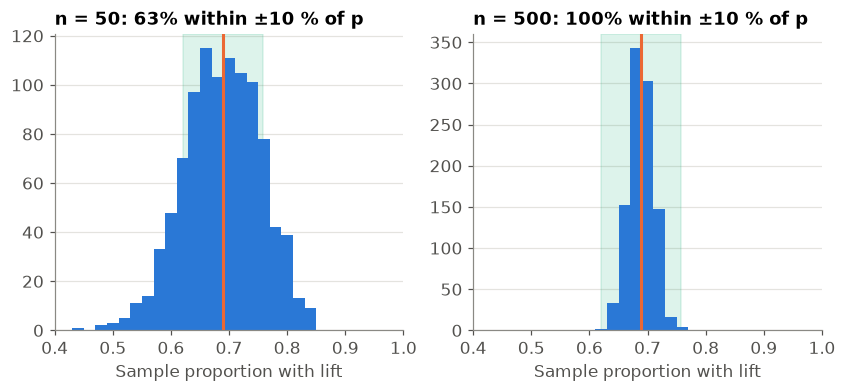

Population proportion p = 0.689


n,mean of p_hat,sd of p_hat,share within ±10 % of p
50,0.688,0.066,0.632
500,0.688,0.021,0.998


In [46]:
lift = population["lift"].to_numpy()
p = lift.mean()
tolerance = 0.10 * p  # ±10 % of the true value, as in the example

rng = np.random.default_rng(2026)
fig, axes = plt.subplots(1, 2, figsize=(9, 3.5), sharex=True)
rows = []
for ax, n in zip(axes, [50, 500]):
    p_hat = np.array([rng.choice(lift, size=n, replace=False).mean() for _ in range(1_000)])
    close = np.abs(p_hat - p) <= tolerance
    rows.append({"n": n, "mean of p_hat": p_hat.mean(), "sd of p_hat": p_hat.std(),
                 "share within ±10 % of p": close.mean()})

    edges = np.arange(-0.01, 1.02, 0.02)  # bins of width 0.02 centred on multiples of 0.02
    ax.axvspan(p - tolerance, p + tolerance, color=COLORS["teal"], alpha=0.15)
    ax.hist(p_hat, bins=edges, color=COLORS["blue"])
    ax.axvline(p, color=COLORS["orange"], linewidth=2)
    ax.set_xlim(0.4, 1)
    ax.set_title(f"n = {n}: {close.mean():.0%} within ±10 % of p")
    ax.set_xlabel("Sample proportion with lift")
plt.show()

print(f"Population proportion p = {p:.3f}")
pl.DataFrame(rows)

The population proportion is $p \approx 0.689$. With both sample sizes the mean of the
1,000 values of $\hat p$ is practically equal to $p$: on average the sample proportion hits
the target. What changes is the spread: with $n = 500$ the standard deviation of $\hat p$ is
about three times smaller than with $n = 50$ (0.021 against 0.066). With $n = 50$, 63 % of
the samples give a proportion within 10 % of $p$ (that is, within about ±0.069), and some
miss it by more than 20 points; with $n = 500$, practically all of them (99.8 %) do.

**e)** In a real study we would have a single sample. With $n = 50$ there is roughly a one in
three chance that our $\hat p$ is more than 10 % away from the truth; with $n = 500$ it is
almost certainly within that margin. Both sample sizes are unbiased, but only the larger one is **reliable**. This is the
practical meaning of a smaller standard deviation: a higher probability that the one
sample we have represents the population well.
:::

## References {.unnumbered}

::: {#refs}
:::